# House Price Prediction — Full Data Science Project
**Dataset:** Indian residential property listings (~187K rows, scraped listing data)
**Goal:** Predict property price (in rupees) from listing attributes.

**Pipeline:** Cleaning → EDA → Feature Engineering → Modeling → Tuning → Evaluation → Export


## 1. Imports & Setup

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

sns.set_style('whitegrid')
pd.set_option('display.max_columns', 50)


## 2. Load Data

In [5]:
df = pd.read_csv(r"C:\Users\win11\Downloads\house_prices.csv\house_prices.csv")
print(df.shape)
df.head()


(187531, 21)


,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN,NaN,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN,NaN,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN,NaN,NaN


In [6]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 187531 entries, 0 to 187530
Data columns (total 21 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Index              187531 non-null  int64  
 1   Title              187531 non-null  str    
 2   Description        184508 non-null  str    
 3   Amount(in rupees)  187531 non-null  str    
 4   Price (in rupees)  169866 non-null  float64
 5   location           187531 non-null  str    
 6   Carpet Area        106858 non-null  str    
 7   Status             186916 non-null  str    
 8   Floor              180454 non-null  str    
 9   Transaction        187448 non-null  str    
 10  Furnishing         184634 non-null  str    
 11  facing             117298 non-null  str    
 12  overlooking        106095 non-null  str    
 13  Society            77853 non-null   str    
 14  Bathroom           186703 non-null  str    
 15  Balcony            138596 non-null  str    
 16  Car Parking  

In [7]:
df.isna().sum().sort_values(ascending=False)


Plot Area            187531
Dimensions           187531
Society              109678
Super Area           107685
Car Parking          103357
overlooking           81436
Carpet Area           80673
facing                70233
Ownership             65517
Balcony               48935
Price (in rupees)     17665
Floor                  7077
Description            3023
Furnishing             2897
Bathroom                828
Status                  615
Transaction              83
Amount(in rupees)         0
Title                     0
Index                     0
location                  0
dtype: int64

## 3. Data Cleaning
The raw data has several problems typical of scraped listings:
- `Amount(in rupees)` is a string like `'42 Lac '` or `'1.40 Cr '` — needs unit parsing
- `Carpet Area` / `Super Area` are strings like `'500 sqft'`
- `Floor` is a string like `'10 out of 11'` or `'Ground out of 7'`
- `Bathroom` / `Balcony` contain `'> 10'` as a literal string
- `Dimensions` and `Plot Area` are entirely empty — drop them
- `Title` / `Description` are free text — not usable as structured features
- Many categorical columns (`Society`, `facing`, `overlooking`, `Car Parking`, `Ownership`) have heavy missingness

In [8]:
# Drop columns that are unusable: fully empty, free text, a duplicate identifier,
# or a target-leaking derivative (Price per sqft is calculated from the total price)
df = df.drop(columns=['Index', 'Title', 'Description', 'Dimensions', 'Plot Area',
                       'Price (in rupees)'])
df.shape


(187531, 15)

In [9]:
# --- Parse Amount(in rupees): '42 Lac ' / '1.40 Cr ' -> rupees ---
def parse_amount(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip()
    m = re.match(r'([\d.]+)\s*(Lac|Cr)', x, re.IGNORECASE)
    if not m:
        return np.nan
    value, unit = float(m.group(1)), m.group(2).lower()
    return value * 1e5 if unit == 'lac' else value * 1e7

df['Total_Price'] = df['Amount(in rupees)'].apply(parse_amount)
df = df.drop(columns=['Amount(in rupees)'])
df[['Total_Price']].describe()


,Total_Price
count,1.778470e+05
mean,1.198134e+07
std,3.943827e+07
min,1.000000e+05
25%,4.840000e+06
50%,7.800000e+06
75%,1.450000e+07
max,1.400300e+10


In [10]:
# --- Parse area columns: '500 sqft' -> 500.0 ---
def parse_area(x):
    if pd.isna(x):
        return np.nan
    m = re.match(r'([\d.]+)', str(x).replace(',', ''))
    return float(m.group(1)) if m else np.nan

df['Carpet_Area_sqft'] = df['Carpet Area'].apply(parse_area)
df['Super_Area_sqft'] = df['Super Area'].apply(parse_area)

# Combine into a single Area feature: prefer Carpet Area, fall back to Super Area
df['Area_sqft'] = df['Carpet_Area_sqft'].fillna(df['Super_Area_sqft'])
df = df.drop(columns=['Carpet Area', 'Super Area', 'Carpet_Area_sqft', 'Super_Area_sqft'])
df['Area_sqft'].describe()


count    186704.000000
mean       1252.464184
std        2659.659913
min           1.000000
25%         800.000000
50%        1140.000000
75%        1551.000000
max      709222.000000
Name: Area_sqft, dtype: float64

In [11]:
# --- Parse Floor: '10 out of 11' / 'Ground out of 7' -> floor_num, total_floors ---
def parse_floor(x):
    if pd.isna(x):
        return np.nan, np.nan
    x = str(x)
    m = re.match(r'(Ground|\d+)\s*out of\s*(\d+)', x, re.IGNORECASE)
    if not m:
        return np.nan, np.nan
    floor_part, total = m.group(1), float(m.group(2))
    floor_num = 0.0 if floor_part.lower() == 'ground' else float(floor_part)
    return floor_num, total

parsed = df['Floor'].apply(parse_floor)
df['floor_num'] = parsed.apply(lambda t: t[0])
df['total_floors'] = parsed.apply(lambda t: t[1])
df = df.drop(columns=['Floor'])
df[['floor_num', 'total_floors']].describe()


,floor_num,total_floors
count,180044.000000,180044.000000
mean,4.454028,8.777249
std,4.661898,7.615343
min,0.000000,1.000000
25%,2.000000,4.000000
50%,3.000000,5.000000
75%,6.000000,11.000000
max,200.000000,200.000000


In [12]:
# --- Clean Bathroom / Balcony: '> 10' -> 11, cast to numeric ---
def clean_count(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip()
    return 11.0 if x == '> 10' else float(x)

df['Bathroom'] = df['Bathroom'].apply(clean_count)
df['Balcony'] = df['Balcony'].apply(clean_count)
df[['Bathroom', 'Balcony']].describe()


,Bathroom,Balcony
count,186703.000000,138596.000000
mean,2.428247,2.001782
std,0.871107,0.958087
min,1.000000,1.000000
25%,2.000000,1.000000
50%,2.000000,2.000000
75%,3.000000,3.000000
max,11.000000,11.000000


In [13]:
# --- Parse Car Parking: '2 Covered' / '1 Open' -> count + type ---
def parse_parking(x):
    if pd.isna(x):
        return np.nan, np.nan
    x = str(x).replace(',', '').strip()
    m = re.match(r'(\d+)\s*(Open|Covered)', x, re.IGNORECASE)
    if not m:
        return np.nan, np.nan
    return float(m.group(1)), m.group(2).capitalize()

parsed_p = df['Car Parking'].apply(parse_parking)
df['parking_count'] = parsed_p.apply(lambda t: t[0])
df['parking_type'] = parsed_p.apply(lambda t: t[1])
df = df.drop(columns=['Car Parking'])
df[['parking_count', 'parking_type']].describe(include='all')


,parking_count,parking_type
count,84174.000000,84174
unique,NaN,2
top,NaN,Covered
freq,NaN,72648
mean,4.036935,NaN
std,31.822614,NaN
min,1.000000,NaN
25%,1.000000,NaN
50%,1.000000,NaN
75%,1.000000,NaN


In [14]:
# --- Group rare locations into 'other' (keep locations with enough listings) ---
loc_counts = df['location'].value_counts()
common_locations = loc_counts[loc_counts >= 300].index
df['location_grouped'] = df['location'].where(df['location'].isin(common_locations), 'other')
df = df.drop(columns=['location'])
df['location_grouped'].value_counts()


location_grouped
new-delhi        27599
bangalore        24030
kolkata          22380
gurgaon          20070
ahmedabad        12750
hyderabad        12300
chennai          10500
jaipur            8490
greater-noida     4710
faridabad         3840
other             3805
vadodara          2388
surat             2370
pune              2225
thane             1933
mumbai            1860
visakhapatnam     1800
mohali            1710
zirakpur          1530
chandigarh        1440
noida             1281
goa               1200
ranchi            1080
bhiwadi           1050
kochi             1050
dehradun           990
ghaziabad          931
lucknow            896
kanpur             780
patna              780
guwahati           750
sonipat            750
coimbatore         720
navi-mumbai        718
nagpur             714
jamshedpur         630
kalyan             600
vijayawada         570
palghar            510
raipur             510
bhubaneswar        456
agra               450
aurangabad       

In [15]:
# --- Drop rows with no target price (can't train/evaluate without it) ---
before = len(df)
df = df.dropna(subset=['Total_Price'])
print(f"Dropped {before - len(df)} rows with missing target price")

# --- Remove obvious data-entry outliers (e.g. near-zero or absurd area/price) ---
df = df[(df['Area_sqft'].isna()) | (df['Area_sqft'].between(50, 20000))]
df = df[df['Total_Price'].between(1e5, 5e8)]  # 1 Lac to 50 Cr, sane listing range
print(df.shape)


Dropped 9684 rows with missing target price
(176752, 16)


In [16]:
# --- Impute remaining missing values ---
numeric_cols = ['Area_sqft', 'Bathroom', 'Balcony', 'floor_num', 'total_floors', 'parking_count']
for c in numeric_cols:
    df[c] = df[c].fillna(df[c].median())

categorical_cols = ['Status', 'Transaction', 'Furnishing', 'facing', 'overlooking',
                     'Society', 'Ownership', 'parking_type']
for c in categorical_cols:
    df[c] = df[c].fillna('Not_Available')

df.isna().sum()


Status              0
Transaction         0
Furnishing          0
facing              0
overlooking         0
Society             0
Bathroom            0
Balcony             0
Ownership           0
Total_Price         0
Area_sqft           0
floor_num           0
total_floors        0
parking_count       0
parking_type        0
location_grouped    0
dtype: int64

In [17]:
# --- Log-transform the skewed target (prices span orders of magnitude) ---
df['Total_Price_log'] = np.log1p(df['Total_Price'])
df.shape


(176752, 17)

## 4. Exploratory Data Analysis

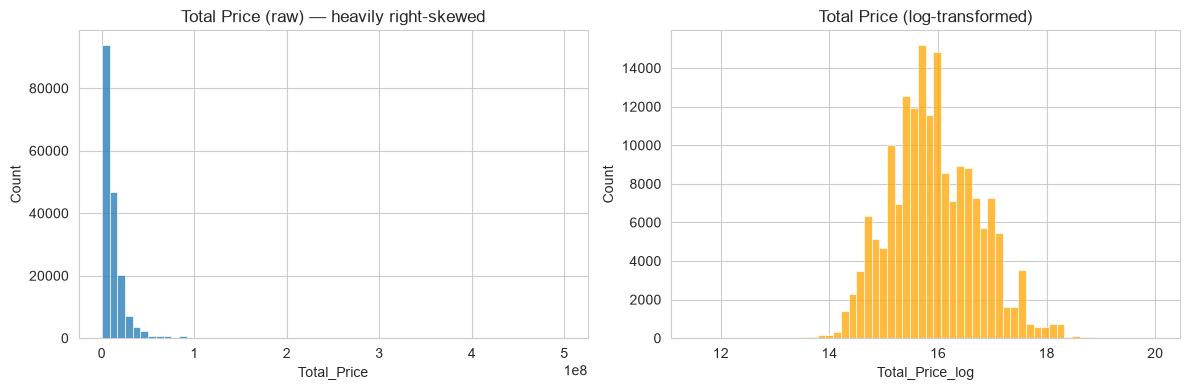

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['Total_Price'], bins=60, ax=axes[0])
axes[0].set_title('Total Price (raw) — heavily right-skewed')
sns.histplot(df['Total_Price_log'], bins=60, ax=axes[1], color='orange')
axes[1].set_title('Total Price (log-transformed)')
plt.tight_layout()
plt.show()


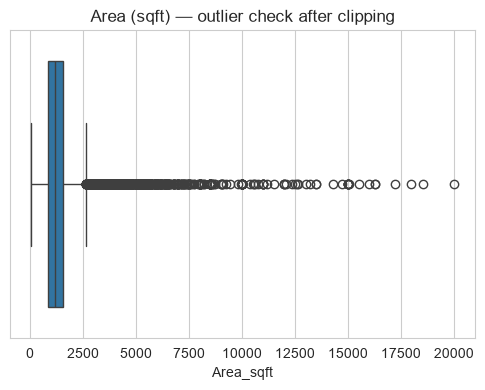

In [19]:
plt.figure(figsize=(6, 4))
sns.boxplot(x=df['Area_sqft'])
plt.title('Area (sqft) — outlier check after clipping')
plt.show()


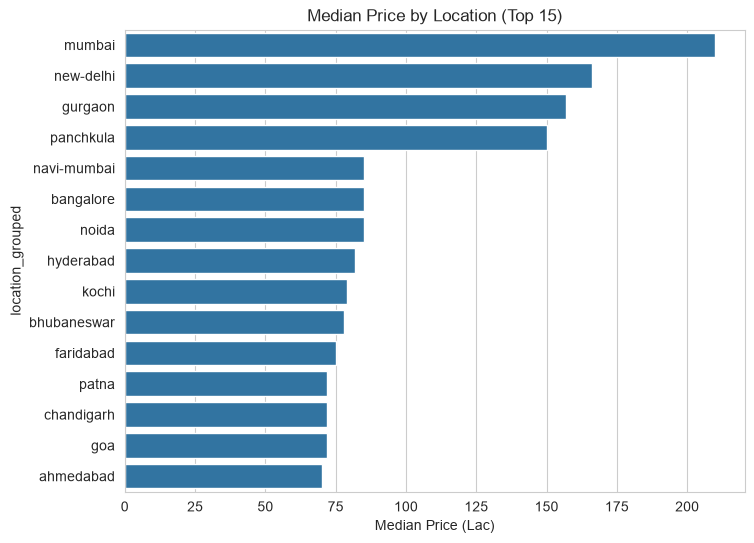

In [20]:
top_locs = df.groupby('location_grouped')['Total_Price'].median().sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 6))
sns.barplot(x=top_locs.values / 1e5, y=top_locs.index)
plt.xlabel('Median Price (Lac)')
plt.title('Median Price by Location (Top 15)')
plt.show()


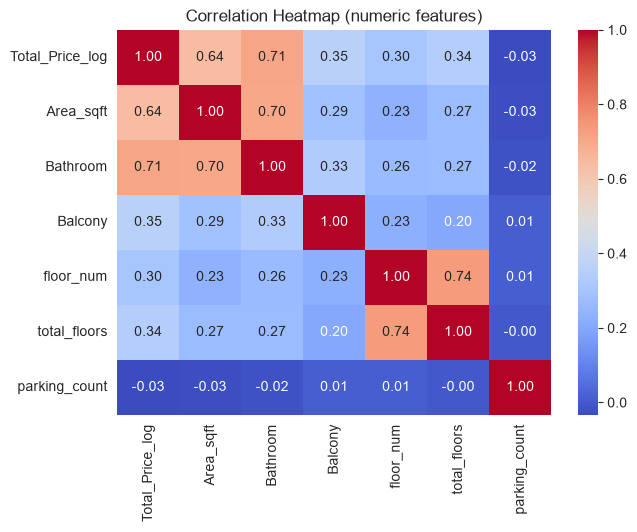

In [21]:
numeric_df = df[['Total_Price_log', 'Area_sqft', 'Bathroom', 'Balcony',
                  'floor_num', 'total_floors', 'parking_count']]
plt.figure(figsize=(7, 5))
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap (numeric features)')
plt.show()


## 5. Feature Engineering — One-Hot Encoding

In [22]:
categorical_features = ['Status', 'Transaction', 'Furnishing', 'facing', 'overlooking',
                         'Ownership', 'parking_type', 'location_grouped']
# 'Society' is extremely high-cardinality free text -> drop rather than one-hot encode
df_model = df.drop(columns=['Society', 'Total_Price'])

df_model = pd.get_dummies(df_model, columns=categorical_features, drop_first=True)
print(df_model.shape)
df_model.head()


(176752, 94)


,Bathroom,Balcony,Area_sqft,floor_num,total_floors,parking_count,Total_Price_log,Status_Ready to Move,Transaction_Not_Available,Transaction_Other,Transaction_Rent/Lease,Transaction_Resale,Furnishing_Not_Available,Furnishing_Semi-Furnished,Furnishing_Unfurnished,facing_North,facing_North - East,facing_North - West,facing_Not_Available,facing_South,facing_South - East,facing_South -West,facing_West,"overlooking_Garden/Park, Main Road","overlooking_Garden/Park, Main Road, Pool",...,location_grouped_kolkata,location_grouped_lucknow,location_grouped_mangalore,location_grouped_mohali,location_grouped_mumbai,location_grouped_nagpur,location_grouped_nashik,location_grouped_navi-mumbai,location_grouped_new-delhi,location_grouped_noida,location_grouped_other,location_grouped_palghar,location_grouped_panchkula,location_grouped_patna,location_grouped_pune,location_grouped_raipur,location_grouped_ranchi,location_grouped_siliguri,location_grouped_sonipat,location_grouped_surat,location_grouped_thane,location_grouped_vadodara,location_grouped_vijayawada,location_grouped_visakhapatnam,location_grouped_zirakpur
0,1.0,2.0,500.0,10.0,11.0,1.0,15.250595,True,False,False,False,True,False,False,True,False,False,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False
1,2.0,2.0,473.0,3.0,22.0,1.0,16.097893,True,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False
2,2.0,2.0,779.0,10.0,29.0,1.0,16.454568,True,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False
3,1.0,1.0,530.0,1.0,3.0,1.0,14.731802,True,False,False,False,True,False,False,True,False,False,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False
4,2.0,2.0,635.0,20.0,42.0,1.0,16.588099,True,False,False,False,True,False,False,True,False,False,False,False,False,False,False,True,True,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False


## 6. Train / Test Split

In [23]:
X = df_model.drop(columns=['Total_Price_log'])
y = df_model['Total_Price_log']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape


((141401, 93), (35351, 93))

## 7. Modeling
### 7.1 Baseline — Linear Regression

In [24]:
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

def evaluate(y_true, y_pred, name):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    print(f"{name:20s}  R2={r2:.4f}   RMSE(log)={rmse:.4f}   MAE(log)={mae:.4f}")
    return {'model': name, 'R2': r2, 'RMSE': rmse, 'MAE': mae}

results = [evaluate(y_test, pred_lr, 'Linear Regression')]


Linear Regression     R2=0.7291   RMSE(log)=0.4266   MAE(log)=0.3222


### 7.2 Random Forest

In [25]:
rf = RandomForestRegressor(n_estimators=200, max_depth=20, min_samples_leaf=2,
                            n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
results.append(evaluate(y_test, pred_rf, 'Random Forest'))


Random Forest         R2=0.9304   RMSE(log)=0.2161   MAE(log)=0.0996


### 7.3 XGBoost

In [26]:
xgb = XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.1,
                    subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42)
xgb.fit(X_train, y_train)
pred_xgb = xgb.predict(X_test)
results.append(evaluate(y_test, pred_xgb, 'XGBoost'))

pd.DataFrame(results)


XGBoost               R2=0.9292   RMSE(log)=0.2180   MAE(log)=0.1205


,model,R2,RMSE,MAE
0,Linear Regression,0.729063,0.426570,0.322215
1,Random Forest,0.930439,0.216142,0.099643
2,XGBoost,0.929216,0.218034,0.120530


## 8. Hyperparameter Tuning (best model: XGBoost)

In [27]:
param_dist = {
    'n_estimators': [200, 300, 400],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.03, 0.05, 0.1],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
}

search = RandomizedSearchCV(
    XGBRegressor(n_jobs=-1, random_state=42),
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
)
search.fit(X_train, y_train)
print("Best params:", search.best_params_)

best_xgb = search.best_estimator_
pred_best = best_xgb.predict(X_test)
results.append(evaluate(y_test, pred_best, 'XGBoost (tuned)'))

pd.DataFrame(results)


Best params: {'subsample': 0.8, 'n_estimators': 300, 'max_depth': 8, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
XGBoost (tuned)       R2=0.9367   RMSE(log)=0.2061   MAE(log)=0.1011


,model,R2,RMSE,MAE
0,Linear Regression,0.729063,0.426570,0.322215
1,Random Forest,0.930439,0.216142,0.099643
2,XGBoost,0.929216,0.218034,0.120530
3,XGBoost (tuned),0.936742,0.206117,0.101101


## 9. Final Evaluation

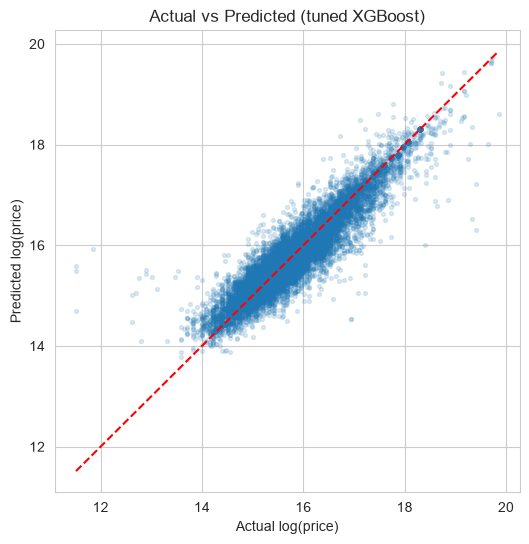

In [28]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_best, alpha=0.15, s=8)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--')
plt.xlabel('Actual log(price)')
plt.ylabel('Predicted log(price)')
plt.title('Actual vs Predicted (tuned XGBoost)')
plt.show()


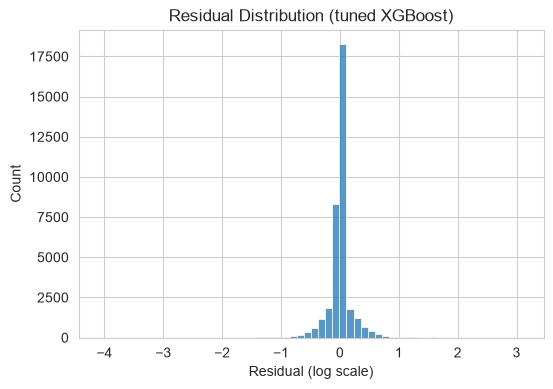

In [29]:
residuals = y_test - pred_best
plt.figure(figsize=(6, 4))
sns.histplot(residuals, bins=60)
plt.title('Residual Distribution (tuned XGBoost)')
plt.xlabel('Residual (log scale)')
plt.show()


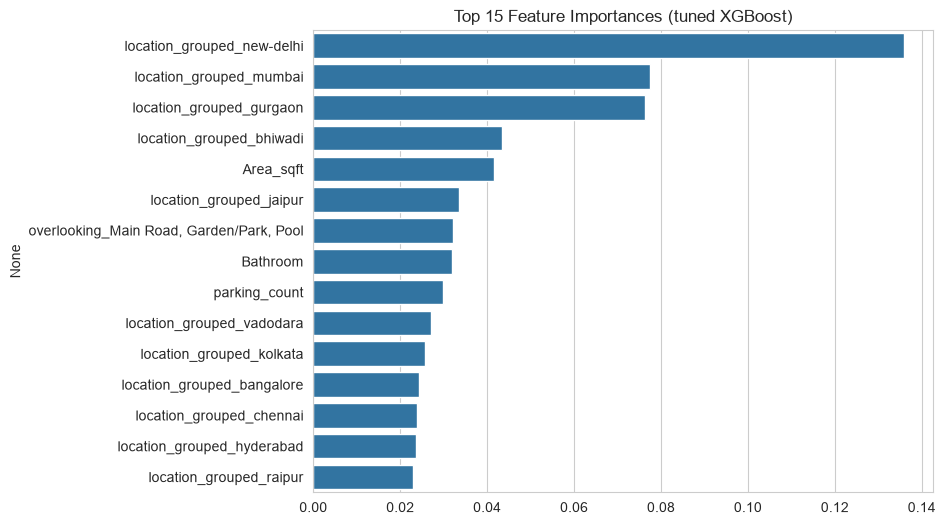

In [30]:
importances = pd.Series(best_xgb.feature_importances_, index=X.columns)
top_features = importances.sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 6))
sns.barplot(x=top_features.values, y=top_features.index)
plt.title('Top 15 Feature Importances (tuned XGBoost)')
plt.show()


## 10. Export Model

In [31]:
joblib.dump(best_xgb, 'house_price_xgb_model.joblib')
joblib.dump(list(X.columns), 'house_price_model_columns.joblib')
print("Saved: house_price_xgb_model.joblib, house_price_model_columns.joblib")
print(f"Final test R2: {r2_score(y_test, pred_best):.4f}")


Saved: house_price_xgb_model.joblib, house_price_model_columns.joblib
Final test R2: 0.9367


## 11. Summary
- Cleaned 21 raw scraped columns into a modeling-ready feature set (parsed price, area, floor, parking; imputed missing values; removed outliers).
- Log-transformed the heavily right-skewed target.
- Compared Linear Regression, Random Forest, and XGBoost; tuned XGBoost with RandomizedSearchCV.
- Exported the final model + column schema for reuse (e.g. a Gradio inference app).